# Predicting Kigali's daily solar radiation multivariate regression

**My Mission.** Nyaruka makes last-mile delivery in Kigali faster, cleaner and more affordable by connecting businesses and customers with e-bicycle riders, through USSD and mobile money so anyone can use it.
E-bicycles are only as efficiency as the energy that charges them, and solar output changes every day with the weather.
This model predicts Kigali's daily solar radiation (MJ/m²/day) from that day's weather, so that Nyaruka team can plan how many e-bicycles its solar charging can power.

- **Source:** NASA POWER (Prediction Of Worldwide Energy Resources), NASA's free satellite-based weather and solar data service.
- **Download the original NASA data in one click:** [NASA POWER direct download (CSV)](https://power.larc.nasa.gov/api/temporal/daily/point?parameters=ALLSKY_SFC_SW_DWN,CLRSKY_SFC_SW_DWN,T2M,T2M_MAX,T2M_MIN,T2MDEW,RH2M,PRECTOTCORR,WS2M,PS&community=AG&longitude=30.0619&latitude=-1.9441&start=20010101&end=20260830&format=CSV)
  - You do not need to search the NASA website or fill in any form. The link already contains every setting used for this project, so NASA sends back the same CSV file straight away.
  - Settings inside the link:
    - `temporal/daily/point`: in order to obtain one value per day for a single location.
    - `latitude=-1.9441&longitude=30.0619`: for the exact location of Kigali, Rwanda.
    - `start=20010101&end=20260830`: 1 January 2001 to 30 August 2026 this enough to be confident.
    - `community=AG`: the agriculture setting, which gives solar radiation in MJ/m²/day.
    - `format=CSV`: a CSV file that opens in Excel or pandas.
    - `parameters=...`: the 10 weather values downloaded:
      - `ALLSKY_SFC_SW_DWN`: solar radiation reaching the ground, with clouds which is our target
      - `CLRSKY_SFC_SW_DWN`: solar radiation on a cloud-free day
      - `T2M`, `T2M_MAX`, `T2M_MIN`: mean, maximum and minimum temperature
      - `T2MDEW`: dew point
      - `RH2M`: relative humidity
      - `PRECTOTCORR`: rain
      - `WS2M`: wind speed
      - `PS`: surface pressure
  - The file starts with an 18 line NASA text header between `-BEGIN HEADER-` and `-END HEADER-`. The data table comes after it, with the date given as `YEAR` and `DOY` (day of the year, 1–366). To load it in pandas, use `pd.read_csv(path, skiprows=18)`.

**Plan.** Explore the data, engineer features, split chronologically, standardize and one-hot encode, then train
SGDRegressor (tuned, with a loss curve), LinearRegression, DecisionTreeRegressor and RandomForestRegressor. The model with the
lowest test MSE is kept, and the whole scikit-learn Pipeline is saved to `../API/best_model.pkl` for the FastAPI service.

In [1]:
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

DATA_PATH = Path("../API/solar_dataset.csv")
MODEL_PATH = Path("../API/best_model.pkl")
TARGET = "solar_radiation_mj"
SEED = 42

## 1. Load and inspect the data

The CSV was built from the NASA POWER daily point API (parameters `ALLSKY_SFC_SW_DWN, CLRSKY_SFC_SW_DWN, T2M, T2M_MAX, T2M_MIN,
T2MDEW, RH2M, PRECTOTCORR, WS2M, PS`, community `AG`). Missing values (NASA's `-999`) and zero-radiation days were dropped, then the
columns were renamed and the engineered columns added.

In [2]:
df = pd.read_csv(DATA_PATH, index_col="date", parse_dates=True).sort_index()
print("shape:", df.shape, "| period:", df.index.min().date(), "->", df.index.max().date())
print("missing values:", int(df.isna().sum().sum()), "| duplicate dates:", int(df.index.duplicated().sum()))
df.head()

shape: (9373, 16) | period: 2001-01-01 -> 2026-08-30
missing values: 0 | duplicate dates: 0


,solar_radiation_mj,clear_sky_radiation_mj,temp_mean_c,temp_max_c,temp_min_c,dew_point_c,humidity_pct,rain_mm,wind_speed_ms,pressure_kpa,temp_range_c,dryness_gap_c,month,quarter,season,rain_category
date,,,,,,,,,,,,,,,,
2001-01-01,14.18,25.93,19.58,24.95,14.53,15.27,78.70,2.22,0.87,83.78,10.42,4.31,January,Q1,DJF_short_dry,light
2001-01-02,17.07,25.56,20.29,26.30,15.26,15.24,75.88,2.23,1.00,83.79,11.04,5.05,January,Q1,DJF_short_dry,light
2001-01-03,19.02,25.16,20.03,26.01,15.20,15.15,76.24,1.26,0.98,83.80,10.81,4.88,January,Q1,DJF_short_dry,light
2001-01-04,15.61,23.99,19.84,26.15,15.06,15.36,78.10,3.94,0.51,83.77,11.09,4.48,January,Q1,DJF_short_dry,light
2001-01-05,10.38,24.58,18.73,21.62,16.61,15.81,84.10,2.51,0.57,83.80,5.01,2.92,January,Q1,DJF_short_dry,light


In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
solar_radiation_mj,9373.0,17.85,3.89,3.94,15.29,18.10,20.66,27.93
clear_sky_radiation_mj,9373.0,25.32,1.78,16.63,24.20,25.73,26.67,28.87
temp_mean_c,9373.0,19.84,1.22,14.92,19.10,19.79,20.60,25.27
temp_max_c,9373.0,25.70,2.02,19.07,24.31,25.58,27.01,33.75
temp_min_c,9373.0,14.90,1.38,8.54,14.21,15.05,15.81,19.35
dew_point_c,9373.0,14.49,1.80,4.86,13.64,14.89,15.76,17.95
humidity_pct,9373.0,74.34,8.64,39.48,68.89,75.71,80.90,93.78
rain_mm,9373.0,3.51,5.60,0.00,0.37,1.60,4.22,82.15
wind_speed_ms,9373.0,1.31,0.30,0.37,1.10,1.31,1.50,2.65
pressure_kpa,9373.0,83.91,0.13,83.51,83.82,83.90,83.99,84.33


## 2. Model inputs and engineered features

The app asks the user for **9 raw values**: max/min/mean temperature, dew point, humidity, rain, wind speed, clear-sky radiation
and the month number. Everything else is derived by `add_derived`, and **the API copies this function exactly**, so the notebook
and the deployed service build identical feature tables.

| Feature | Type | Why |
|---|---|---|
| `temp_range_c` = max − min | engineered numeric | clear skies give hot days and cold nights, so a large range usually means more sun |
| `dryness_gap_c` = mean − dew point | engineered numeric | a small gap means humid, cloudy air |
| `month` | categorical (one-hot) | the sun's position and the rainy seasons follow the calendar |
| `season` | categorical (one-hot) | Rwanda's four seasons (two dry, two rainy) |
| `rain_category` | categorical (one-hot) | dry / light / moderate / heavy rain, a non-linear view of rainfall |

Columns that are **not** used: `pressure_kpa` (correlation +0.03 with the target, std only 0.13 kPa, range 83.5–84.3 kPa),
and `quarter` (redundant with `month` and `season`). The target is never used to build a feature.

In [4]:
RAW_NUMERIC = ["temp_max_c", "temp_min_c", "temp_mean_c", "dew_point_c", "humidity_pct",
               "rain_mm", "wind_speed_ms", "clear_sky_radiation_mj"]
NUM_FEATURES = RAW_NUMERIC + ["temp_range_c", "dryness_gap_c"]
CAT_FEATURES = ["month", "season", "rain_category"]
FEATURES = NUM_FEATURES + CAT_FEATURES

MONTHS = ["January", "February", "March", "April", "May", "June", "July",
          "August", "September", "October", "November", "December"]
SEASONS = ["DJF_short_dry", "MAM_long_rains", "JJA_long_dry", "SON_short_rains"]
RAIN_CATS = ["dry", "light", "moderate", "heavy"]


def add_derived(raw: pd.DataFrame) -> pd.DataFrame:
    # raw has the 8 RAW_NUMERIC columns plus month_num (1-12). Returns all FEATURES.
    out = raw.copy()
    out["temp_range_c"] = out["temp_max_c"] - out["temp_min_c"]
    out["dryness_gap_c"] = out["temp_mean_c"] - out["dew_point_c"]
    m = out["month_num"].astype(int)
    out["month"] = [MONTHS[i - 1] for i in m]
    out["season"] = np.select(
        [m.isin([12, 1, 2]), m.isin([3, 4, 5]), m.isin([6, 7, 8])],
        ["DJF_short_dry", "MAM_long_rains", "JJA_long_dry"], "SON_short_rains")
    out["rain_category"] = pd.cut(out["rain_mm"], [-np.inf, 1, 5, 15, np.inf],
                                  labels=RAIN_CATS).astype(str)
    return out


# Rebuild the features from the 9 raw inputs only and check they match the CSV.
raw = df[RAW_NUMERIC].copy()
raw["month_num"] = df.index.month
X_all = add_derived(raw)[FEATURES]
y_all = df[TARGET]
for col in ["temp_range_c", "dryness_gap_c"]:
    assert np.allclose(X_all[col], df[col]), col
for col in CAT_FEATURES:
    assert (X_all[col].astype(str) == df[col].astype(str)).all(), col
print("add_derived reproduces the dataset's engineered columns:", X_all.shape)

add_derived reproduces the dataset's engineered columns: (9373, 13)


## 3. Visualisation 1 correlation heatmap

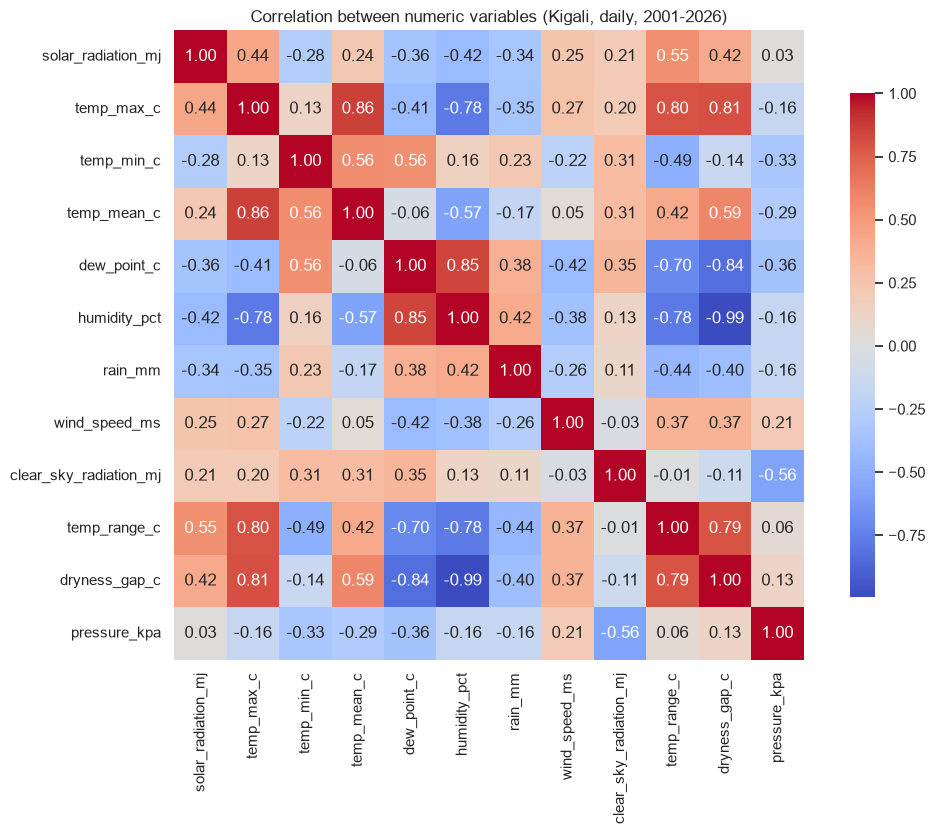

Correlation with the target:
temp_range_c              0.550
temp_max_c                0.437
dryness_gap_c             0.421
humidity_pct             -0.419
dew_point_c              -0.361
rain_mm                  -0.343
temp_min_c               -0.275
wind_speed_ms             0.246
temp_mean_c               0.236
clear_sky_radiation_mj    0.207
pressure_kpa              0.026


In [5]:
num_cols = [TARGET] + NUM_FEATURES + ["pressure_kpa"]
corr = df[num_cols].corr()
plt.figure(figsize=(11, 8.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .8})
plt.title("Correlation between numeric variables (Kigali, daily, 2001-2026)")
plt.tight_layout()
plt.show()
print("Correlation with the target:")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_string())

**Conclusions from the heatmap.**
- This Indicates that The strongest single signal is the engineered **`temp_range_c` r = +0.55**: that means that clear days heat up and clear nights cool down if you lived in kigali you can already conclude this, cloudy days stay flat. The other engineered feature, **`dryness_gap_c` +0.42**, is as strong as `temp_max_c` (+0.44) and humidity (−0.42). Both engineered features earn their place.
- Humidity, dew point and rain are negative: moist, rainy days are also cloudy days.
- `clear_sky_radiation_mj` is only +0.21. because Kigali is 2° south of the equator, so the clear-sky ceiling hardly changes over the year (std 1.8 MJ/m²/day); clouds, not the sun's position, decide the day.
- `pressure_kpa` is practically uncorrelated +0.03 and barely varies std at 0.13 kPa, so it is **dropped**.
- Several inputs are strongly inter-correlated for example humidity with dew point and dryness gap, and `temp_range_c` is exactly max − min. This multicollinearity does not hurt our predictions, but it makes individual linear coefficients unreliable to explain. The penalty chosen for SGD below which is below the L1 makes little difference: by the we can conclude saying that the three penalties differ by only about 0.01 in CV MSE.

## 4. Visualisation 2 distributions histograms

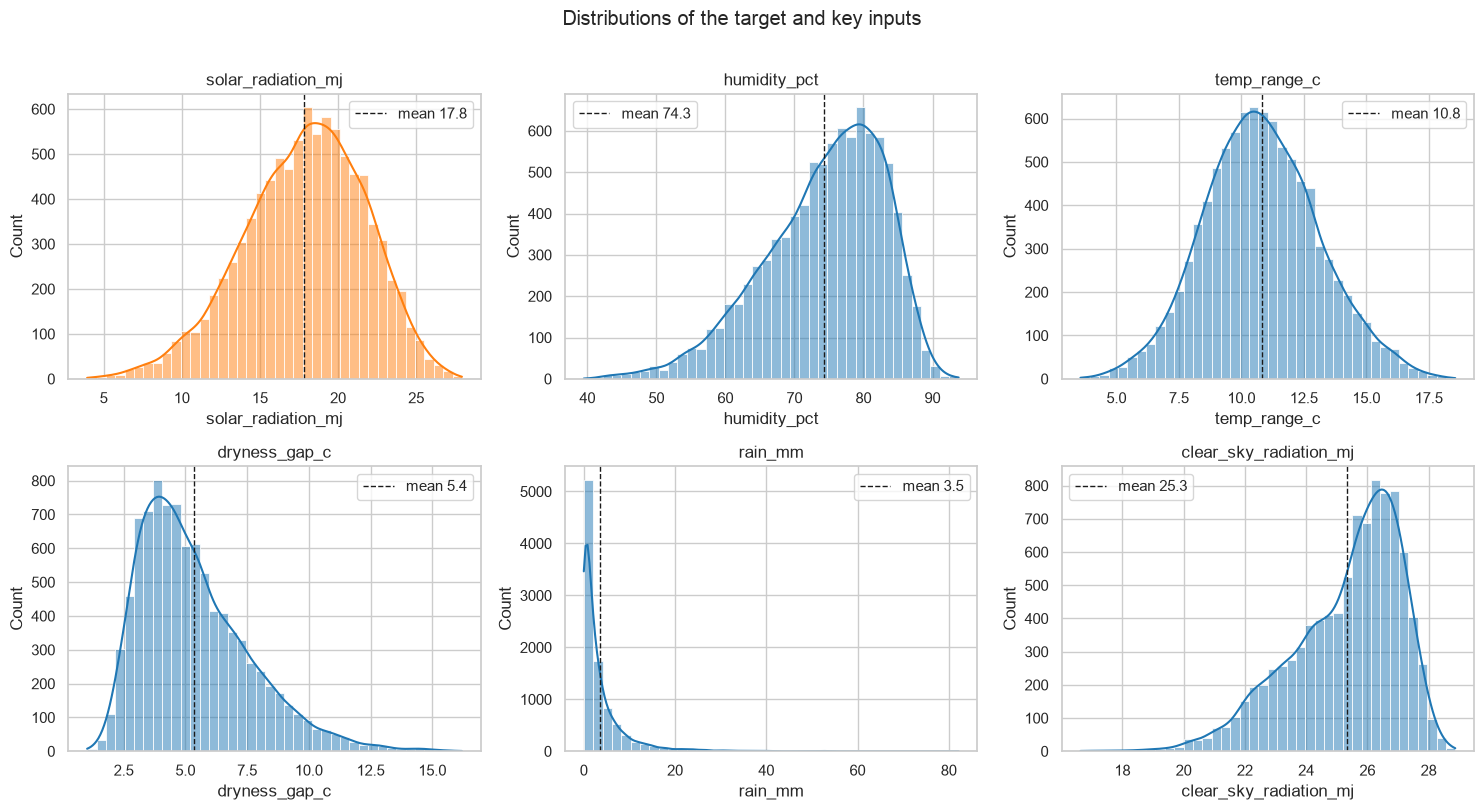

                         mean  median   std  skew
solar_radiation_mj      17.85   18.10  3.89 -0.34
humidity_pct            74.34   75.71  8.64 -0.71
temp_range_c            10.81   10.73  2.29  0.14
dryness_gap_c            5.35    4.87  2.23  1.04
rain_mm                  3.51    1.60  5.60  4.08
clear_sky_radiation_mj  25.32   25.73  1.78 -0.86


In [6]:
hist_cols = [TARGET, "humidity_pct", "temp_range_c", "dryness_gap_c", "rain_mm", "clear_sky_radiation_mj"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), hist_cols):
    sns.histplot(df[col], bins=40, kde=True, ax=ax, color="tab:orange" if col == TARGET else "tab:blue")
    ax.axvline(df[col].mean(), color="k", ls="--", lw=1, label=f"mean {df[col].mean():.1f}")
    ax.set_title(col)
    ax.legend()
plt.suptitle("Distributions of the target and key inputs", y=1.01)
plt.tight_layout()
plt.show()
print(df[hist_cols].agg(["mean", "median", "std", "skew"]).T.round(2))

**Conclusions from the histograms.**
- **Target**: The roughly bell-shaped we are observing around 17.8 MJ/m²/day with median of 18.1 and with a mild left tail skew −0.34 down to 3.9: this simply means a few very overcast days, no extreme sunny outliers through the observation. A squared-error loss (MSE) is reasonable for it.
- **Rain** is extremely right-skewed at skew of 4.1, median 1.6 mm, max 82 mm: this means that half the days have under 1.6 mm of rain. A straight line in millimetres cannot capture that, so `rain_category` (dry / light / moderate / heavy) gives the linear models a non-linear view of rain.
- **Humidity**  with skew of −0.71 and **clear-sky radiation** of −0.86 lean left, and **dryness gap** leans right at +1.04. None is extreme enough to need a log transform; standardizing is enough.
- **Temperature range** is close to normal, which suits a linear model, and it is the best single predictor.

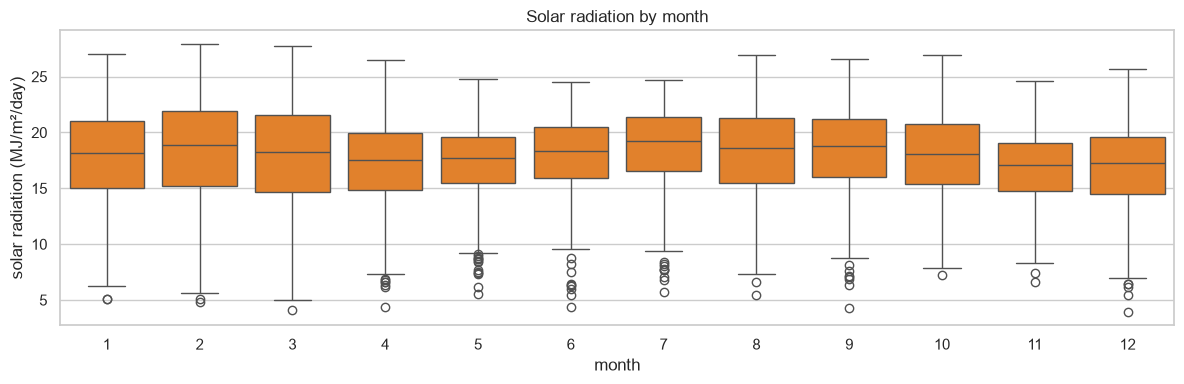

date
1     17.92
2     18.47
3     17.93
4     17.17
5     17.36
6     18.01
7     18.74
8     18.23
9     18.44
10    18.00
11    16.89
12    16.99


In [7]:
plt.figure(figsize=(12, 4))
sns.boxplot(x=df.index.month, y=df[TARGET], color="tab:orange")
plt.xlabel("month")
plt.ylabel("solar radiation (MJ/m²/day)")
plt.title("Solar radiation by month")
plt.tight_layout()
plt.show()
print(df.groupby(df.index.month)[TARGET].mean().round(2).to_string())

**Seasonality.** Monthly means only move between 16.9 from November and 18.7 July MJ/m²/day. Only April to May 17.2, 17.4 and November to December 16.9, 17.0, the core of the two rainy seasons, are clearly lowest, and July 18.7 is highest; March 17.9 and June 18.0 ist at close to the yearly average of 17.9. The spread *within* every month is far larger than the difference *between* months, so the day's weather matters much more than the calendar. this is why we need to give our model weather input instead of relying on the months inputs

## 5. Chronological train test split and preprocessing

The data we have is a time series, so if we do a random split would let the model trying to see the future. yet our We train on a  **2001 to 2021** and test on
**From 2022 onwards**. Numeric columns are standardized with mean 0, std 1, needed for gradient descent, and the categorical columns are
one hot encoded with fixed category lists so a single row from the API always produces the same columns. All tuning uses
`TimeSeriesSplit` The cross validation on the training years only; the test years are only used for the final comparison.

In [8]:
train_mask = X_all.index.year <= 2021
X_train, X_test = X_all[train_mask], X_all[~train_mask]
y_train, y_test = y_all[train_mask], y_all[~train_mask]
print(f"train: {len(X_train)} rows ({X_train.index.min().date()} -> {X_train.index.max().date()})")
print(f"test : {len(X_test)} rows ({X_test.index.min().date()} -> {X_test.index.max().date()})")


def make_prep() -> ColumnTransformer:
    return ColumnTransformer([
        ("num", StandardScaler(), NUM_FEATURES),
        ("cat", OneHotEncoder(categories=[MONTHS, SEASONS, RAIN_CATS], handle_unknown="ignore",
                              sparse_output=False), CAT_FEATURES),
    ])


cv = TimeSeriesSplit(n_splits=5)
print("columns after preprocessing:", make_prep().fit(X_train).transform(X_train.head()).shape[1])

train: 7670 rows (2001-01-01 -> 2021-12-31)
test : 1703 rows (2022-01-01 -> 2026-08-30)
columns after preprocessing: 30


## 6. Linear regression with gradient descent (SGDRegressor) tuning

Grid search over four hyperparameters with 5 fold time series cross validation (score: MSE):
`alpha` (regularisation strength), `penalty` (L2, L1, elastic-net), `eta0` (initial learning rate) and `learning_rate`
(schedule: `invscaling` shrinks the step every update, `constant` keeps it fixed).

In [9]:
sgd_pipe = Pipeline([("prep", make_prep()),
                     ("model", SGDRegressor(max_iter=2000, tol=1e-5, random_state=SEED))])
sgd_grid = {
    "model__alpha": [1e-5, 1e-4, 1e-3, 1e-2, 1e-1],
    "model__penalty": ["l2", "l1", "elasticnet"],
    "model__eta0": [0.001, 0.01, 0.05],
    "model__learning_rate": ["invscaling", "constant"],
}
sgd_search = GridSearchCV(sgd_pipe, sgd_grid, cv=cv, scoring="neg_mean_squared_error", n_jobs=-1)
sgd_search.fit(X_train, y_train)
best_sgd_params = {k.replace("model__", ""): v for k, v in sgd_search.best_params_.items()}
print("best SGD hyperparameters:", best_sgd_params)
print(f"best CV MSE: {-sgd_search.best_score_:.4f}")

best SGD hyperparameters: {'alpha': 0.001, 'eta0': 0.001, 'learning_rate': 'invscaling', 'penalty': 'l1'}
best CV MSE: 8.2836


**How each hyperparameter changes the loss** one hyperparameter is varied at a time, the other three stay at their best values CV MSE on the training years.

In [10]:
res = pd.DataFrame(sgd_search.cv_results_)
res["cv_mse"] = -res["mean_test_score"]
best = sgd_search.best_params_
sgd_tables = {}
for p in sgd_grid:
    others = [q for q in sgd_grid if q != p]
    mask = np.logical_and.reduce([res[f"param_{q}"] == best[q] for q in others])
    t = res.loc[mask, [f"param_{p}", "cv_mse"]].rename(columns={f"param_{p}": p.replace("model__", "")})
    sgd_tables[p] = t.set_index(t.columns[0]).round(4)
    display(sgd_tables[p].T)

alpha,0.00001,0.00010,0.00100,0.01000,0.10000
cv_mse,8.2954,8.2907,8.2836,8.3292,9.1379


penalty,l2,l1,elasticnet
cv_mse,8.295,8.2836,8.2914


eta0,0.001,0.010,0.050
cv_mse,8.2836,8.2907,8.3922


learning_rate,invscaling,constant
cv_mse,8.2836,8.3216


In [11]:
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import cross_val_score

# Number of epochs: every other hyperparameter stays at the saved model's value.
# tol=None forces exactly `max_iter` passes over the data (no early stop).
# Same 5-fold TimeSeriesSplit on the training years as the tables above; the test years are not used.
EPOCH_GRID = [1, 2, 3, 5, 10, 25, 50, 100, 200]
epoch_rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=ConvergenceWarning)
    for n in EPOCH_GRID:
        pipe = Pipeline([("prep", make_prep()),
                         ("model", SGDRegressor(**best_sgd_params, max_iter=n, tol=None, random_state=SEED))])
        scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="neg_mean_squared_error", n_jobs=-1)
        epoch_rows.append({"epochs": n, "cv_mse": -scores.mean()})
sgd_tables["epochs"] = pd.DataFrame(epoch_rows).set_index("epochs").round(4)
display(sgd_tables["epochs"].T)

saved_epochs = sgd_search.best_estimator_.named_steps["model"].n_iter_
print(f"saved model: max_iter=2000, tol=1e-5 (early stop) -> stopped after {saved_epochs} epochs, "
      f"CV MSE {-sgd_search.best_score_:.4f}")

epochs,1,2,3,5,10,25,50,100,200
cv_mse,67.846,33.4457,21.7529,13.6721,9.733,8.799,8.6346,8.518,8.4181


saved model: max_iter=2000, tol=1e-5 (early stop) -> stopped after 389 epochs, CV MSE 8.2836


**Number of epochs.** The validation loss falls steeply after the first passes CV MSE 67.8 after 1 epoch, 13.7 after 5, 9.73 after 10, because with the small `eta0 = 0.001` and a step that keeps reducing `invscaling`, a few passes are far from enough. From about 25 epochs 8.80 the gains become small 8.63 at 50, 8.52 at 100, 8.42 at 200, about 0.1 per doubling, and the saved model's setting, which keeps training until the loss stops improving by more than 1e-5 389 epochs on the full training years, reaches the lowest value, 8.2836, so no fixed epoch count in the table beats it.

### Loss curve (gradient descent, epoch by epoch)

A fresh SGDRegressor with the tuned hyperparameters is trained one epoch at a time with `partial_fit`; after every epoch we record
the MSE on the training years and on the test years.

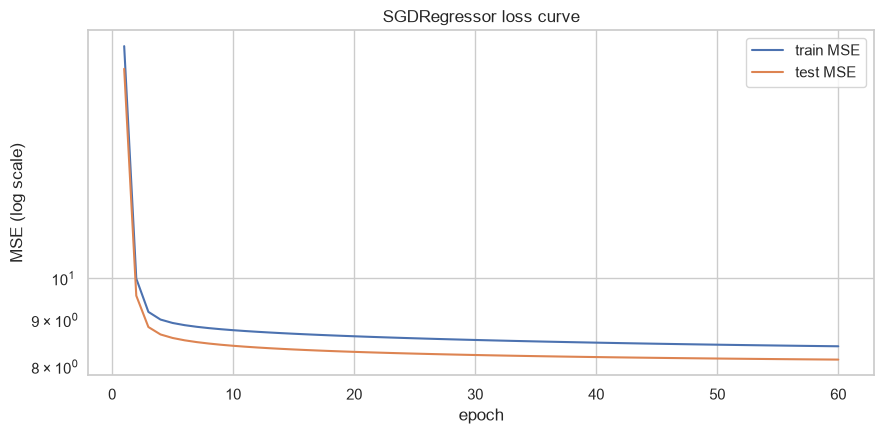

epoch 1: train 17.960, test 16.962 | epoch 60: train 8.423, test 8.145


In [12]:
prep_lc = make_prep().fit(X_train)
Xtr_t, Xte_t = prep_lc.transform(X_train), prep_lc.transform(X_test)
sgd_lc = SGDRegressor(**best_sgd_params, random_state=SEED)
train_loss, test_loss = [], []
EPOCHS = 60
for epoch in range(EPOCHS):
    sgd_lc.partial_fit(Xtr_t, y_train)
    train_loss.append(mean_squared_error(y_train, sgd_lc.predict(Xtr_t)))
    test_loss.append(mean_squared_error(y_test, sgd_lc.predict(Xte_t)))

plt.figure(figsize=(9, 4.5))
plt.plot(range(1, EPOCHS + 1), train_loss, label="train MSE")
plt.plot(range(1, EPOCHS + 1), test_loss, label="test MSE")
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("MSE (log scale)")
plt.title("SGDRegressor loss curve")
plt.legend()
plt.tight_layout()
plt.show()
print(f"epoch 1: train {train_loss[0]:.3f}, test {test_loss[0]:.3f} | "
      f"epoch {EPOCHS}: train {train_loss[-1]:.3f}, test {test_loss[-1]:.3f}")

**Interpreting the loss curve.** The training MSE falls from 17.96 after epoch 1 to 9.19 after epoch 3 and 8.77 after epoch 10, then after that it starts to flattens slowly to 8.42 by the point we reach to the epoch 60 by test: 8.15. The epochs table above shows higher MSE at the same epoch count of 21.75 after 3 epochs because it averages 5 CV folds whose training sets are smaller remember that the first has only 1,280 days against 7,670 here, and one epoch over fewer days means fewer gradient updates, so those fits are further from the minimum. The two curves stay close and the test curve never turns upward, so we can conclude that the model is **not overfitting**: instead it is limited by what a linear model can explain from these inputs which are also known as high bias, not by too little training. The test MSE is slightly *lower* than the train MSE, likely because the 2022 to 2026 days are a little easier to predict, not because of any leakage: the split is chronological and the scaler is fitted on the training years only. Tuning was done only on the training years.

## 7. Other models: LinearRegression, DecisionTree, RandomForest

`LinearRegression` is the exact least squares solution of the same linear model no tuning really needed. The two tree models get a small
grid search with the same time series CV. Trees do not need scaling, but using the same preprocessing keeps a single API input format.

In [13]:
def search(model, grid):
    pipe = Pipeline([("prep", make_prep()), ("model", model)])
    g = GridSearchCV(pipe, {f"model__{k}": v for k, v in grid.items()}, cv=cv,
                     scoring="neg_mean_squared_error", n_jobs=-1)
    g.fit(X_train, y_train)
    print(type(model).__name__, {k.replace("model__", ""): v for k, v in g.best_params_.items()},
          f"CV MSE {-g.best_score_:.4f}")
    return g.best_estimator_


lin_pipe = Pipeline([("prep", make_prep()), ("model", LinearRegression())]).fit(X_train, y_train)
tree_pipe = search(DecisionTreeRegressor(random_state=SEED),
                   {"max_depth": [4, 6, 8, 10, None], "min_samples_leaf": [1, 5, 20, 50]})
forest_pipe = search(RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1),
                     {"max_depth": [8, 12, 16], "min_samples_leaf": [5, 10], "max_features": [0.5, 1.0]})
sgd_best_pipe = sgd_search.best_estimator_

DecisionTreeRegressor {'max_depth': 8, 'min_samples_leaf': 50} CV MSE 9.7429
RandomForestRegressor {'max_depth': 12, 'max_features': 1.0, 'min_samples_leaf': 10} CV MSE 8.6474


## 8. Model comparison (lowest test MSE wins)

In [14]:
models = {"SGDRegressor (gradient descent)": sgd_best_pipe, "LinearRegression": lin_pipe,
          "DecisionTreeRegressor": tree_pipe, "RandomForestRegressor": forest_pipe}
rows = []
for name, m in models.items():
    p_tr, p_te = m.predict(X_train), m.predict(X_test)
    rows.append({"model": name,
                 "train_MSE": mean_squared_error(y_train, p_tr),
                 "test_MSE": mean_squared_error(y_test, p_te),
                 "test_RMSE": np.sqrt(mean_squared_error(y_test, p_te)),
                 "test_R2": r2_score(y_test, p_te)})
comparison = pd.DataFrame(rows).set_index("model").sort_values("test_MSE").round(4)
display(comparison)
best_name = comparison.index[0]
best_model = models[best_name]
baseline = mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))
print(f"Best model: {best_name} (test MSE {comparison.loc[best_name, 'test_MSE']:.4f})")
print(f"For scale: predicting the training mean every day gives test MSE {baseline:.4f}; "
      f"target variance on test = {y_test.var():.4f}")

,train_MSE,test_MSE,test_RMSE,test_R2
model,,,,
SGDRegressor (gradient descent),8.2435,8.0833,2.8431,0.4515
LinearRegression,8.2291,8.0931,2.8448,0.4508
RandomForestRegressor,5.5250,8.1674,2.8579,0.4458
DecisionTreeRegressor,8.1382,9.0122,3.0020,0.3884


Best model: SGDRegressor (gradient descent) (test MSE 8.0833)
For scale: predicting the training mean every day gives test MSE 14.7988; target variance on test = 14.7449


**Result.** The tuned **SGDRegressor has the lowest test MSE at 8.08** and is saved for the API, but against the exact `LinearRegression` solution of 8.09 it is almost considered a tie, which is we would expect because the gradient descent is converging to almost the same straight line model.

**How the dataset affected each model.**
- The relationships here are mostly always **smooth and close to linear** in order to fully visualize this, see the heatmap and the scatter plots in section 9 our book, and the data is noisy. Linear models capture the trend without fitting the noise, so their train and test MSE are almost nearly equal.
- **RandomForest** has a much lower train MSE of 5.5 than test MSE with 8.2: it memorizes part of the noise.This extra adaptability it helps nothing on unseen years, because there is little non linear structure left to find in these inputs.
- A single **DecisionTree** is worst at 9.0 . It predicts in steps, a poor fit for a smooth target, and it overfits more than the forest, which averages 100 trees.
- The three best models stop near R² ≈ 0.45. The main driver of daily radiation is **cloud**, which is only measured indirectly here through temperature range, humidity and rain. That ceiling comes from the data, not from the algorithm.

## 9. Scatter plots

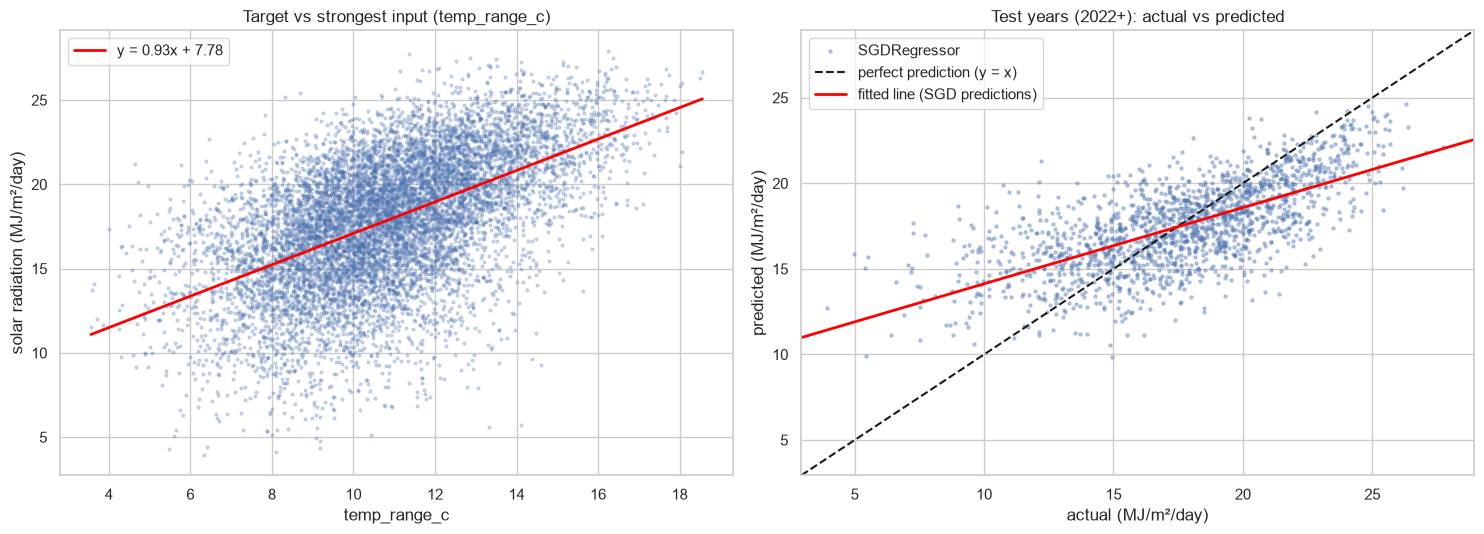

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# (a) before modelling: the strongest single input against the target, with a fitted straight line
top = corr[TARGET].drop(TARGET).abs().idxmax()
axes[0].scatter(df[top], df[TARGET], s=4, alpha=.25)
slope, intercept = np.polyfit(df[top], df[TARGET], 1)
xs = np.linspace(df[top].min(), df[top].max(), 100)
axes[0].plot(xs, slope * xs + intercept, color="red", lw=2,
             label=f"y = {slope:.2f}x + {intercept:.2f}")
axes[0].set_xlabel(top)
axes[0].set_ylabel("solar radiation (MJ/m²/day)")
axes[0].set_title(f"Target vs strongest input ({top})")
axes[0].legend()

# (b) after training: actual vs predicted on the test years, linear model vs best model
lim = [y_all.min() - 1, y_all.max() + 1]
axes[1].scatter(y_test, sgd_best_pipe.predict(X_test), s=5, alpha=.35, label="SGDRegressor")
if best_name != "SGDRegressor (gradient descent)":
    axes[1].scatter(y_test, best_model.predict(X_test), s=5, alpha=.35, label=best_name)
axes[1].plot(lim, lim, "k--", lw=1.5, label="perfect prediction (y = x)")
fit = np.polyfit(y_test, sgd_best_pipe.predict(X_test), 1)
axes[1].plot(lim, np.polyval(fit, lim), color="red", lw=2, label="fitted line (SGD predictions)")
axes[1].set_xlim(lim); axes[1].set_ylim(lim)
axes[1].set_xlabel("actual (MJ/m²/day)")
axes[1].set_ylabel("predicted (MJ/m²/day)")
axes[1].set_title("Test years (2022+): actual vs predicted")
axes[1].legend()
plt.tight_layout()
plt.show()

**Reading the scatter plots.** On the left, the fitted line y = 0.93x + 7.78 shows radiation rising by about 0.93 MJ/m²/day for each extra °C of temperature range, but with R² ≈ 0.30 with r = 0.550 squared, from the heatmap this single input leaves most of the day-to-day spread unexplained. On the right, the red line fitted through the SGD test predictions is much flatter than the y = x diagonal, so the model pulls its predictions toward the average: it over-predicts the cloudiest days and under-predicts the sunniest ones.

## 10. Save the best model

In [16]:
joblib.dump(best_model, MODEL_PATH, compress=3)
print(f"saved {best_name} pipeline (steps: {[s for s, _ in best_model.steps]}) to {MODEL_PATH.resolve()}")
print(f"file size: {MODEL_PATH.stat().st_size / 1024:.1f} KB ({MODEL_PATH.stat().st_size / 1e6:.4f} MB)")

saved SGDRegressor (gradient descent) pipeline (steps: ['prep', 'model']) to /Users/igorntwali/dev/linear_regression_model/summative/API/best_model.pkl
file size: 2.3 KB (0.0023 MB)


## 11. Predict one day

`predict_one` takes the same 9 raw values as the app and the API, runs `add_derived`, and calls the saved pipeline.

In [17]:
loaded = joblib.load(MODEL_PATH)


def predict_one(temp_max_c, temp_min_c, temp_mean_c, dew_point_c, humidity_pct, rain_mm,
                wind_speed_ms, clear_sky_radiation_mj, month_num, model=loaded) -> float:
    raw = pd.DataFrame([{"temp_max_c": temp_max_c, "temp_min_c": temp_min_c, "temp_mean_c": temp_mean_c,
                         "dew_point_c": dew_point_c, "humidity_pct": humidity_pct, "rain_mm": rain_mm,
                         "wind_speed_ms": wind_speed_ms, "clear_sky_radiation_mj": clear_sky_radiation_mj,
                         "month_num": month_num}])
    return float(model.predict(add_derived(raw)[FEATURES])[0])


row = df.loc[X_test.index[-1]]
pred = predict_one(**{c: row[c] for c in RAW_NUMERIC}, month_num=X_test.index[-1].month)
print(f"{X_test.index[-1].date()}: predicted {pred:.2f} MJ/m²/day ({pred / 3.6:.2f} kWh/m²/day), "
      f"actual {row[TARGET]:.2f} MJ/m²/day")
print("a dry, clear July day :", round(predict_one(27, 13, 20, 9, 55, 0, 1.6, 25, 7), 2), "MJ/m²/day")
print("a wet, cloudy April day:", round(predict_one(23, 16, 19, 17, 90, 20, 1.0, 26, 4), 2), "MJ/m²/day")

2026-08-30: predicted 23.84 MJ/m²/day (6.62 kWh/m²/day), actual 25.08 MJ/m²/day
a dry, clear July day : 23.37 MJ/m²/day
a wet, cloudy April day: 14.1 MJ/m²/day


## 12. Discussion

**Is the test loss high or low?** Test with MSE = 8.08, RMSE ≈ 2.8 MJ/m²/day, about 16% of the average day. That is a 45% lower than always predicting the average with MSE of 14.8, so we can confidently say that the model is useful for planning, but it is only moderate with R² of  0.45. It cannot tell apart two days with similar temperatures and humidity but different cloud cover. in order to reduce it, while keeping the same NASA POWER source dataset: we could introduce a cloud-related variable or yesterday's radiation as an input. A more complex model would not help much either, because the random forest did no better on the test years with MSE of 8.17 against 8.08, and more training years would not help much also, because the loss curve shows no overfitting.

**Hyperparameters tuned (SGDRegressor, 5-fold time-series CV MSE, tables above):**
- `alpha` (CV MSE): 1e-5: 8.295, 1e-4: 8.291, **1e-3: 8.284**, 1e-2: 8.329, 1e-1: 9.138. 1e-5 to 1e-3 are within about 0.01 of each other; only 0.1 is clearly worse.
- `penalty`: **L1: 8.284**, elastic-net: 8.291, L2: 8.295. The three penalties differ by only about 0.01 in CV MSE, so the choice of L1 barely matters.
- `eta0`: **0.001: 8.284**, 0.01: 8.291, 0.05: 8.392. Bigger first steps probably make the updates noisier.
- `learning_rate`: **invscaling: 8.284**, constant: 8.322. A step that shrinks over time probably settles closer to the minimum.

**What happens when new data arrives?** The API's `/retrain` endpoint accepts a CSV with new days. Because the saved model is an SGDRegressor, the API keeps the already-fitted scaler and encoder and continues training the same model with `partial_fit` on the new rows. The updated model replaces the one in memory at once, without a redeploy.

- **Limitation:** NASA's radiation and its weather values both come from NASA satellite and reanalysis products, so the model learns relationships inside one modelled system, not between independent ground sensors and a forecast. Unfortunately Kigali has very few ground solar sensors.the next step is to cross-check the results against other independent satellite radiation product.